# Work dates
How many individuals can be placed in time by the dates of their works, and in which centuries. Works only, taken from notebook 15; Wikidata values only.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import polars as pl

from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'

FIRST_CENTURY = -1000
LAST_CENTURY = 2000
PRECISE = ['day', 'month', 'year', 'decade']
MID_DECADE = 5

pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(80)

SERIES_COLORS = {
    'At least 2 precise works': BLUE,
    'Only 1 precise work': LIGHT_BLUE,
    'At least 1 precise work': NAVY,
}

apply_style()

connection = duckdb.connect(DB_PATH, read_only=True)

## Load the data
A work's date is its publication date, else its inception, as for `works_period`. A decade-precise date is moved to the middle of its decade. Each individual gets one row: dated works, precise dated works, earliest precise work year.

In [2]:
works = connection.execute('''
    WITH dated AS (
        SELECT individual_work.qid,
               individual_work.work_qid,
               coalesce(work.publication_date.year, work.inception.year) AS year,
               CASE WHEN work.publication_date.year IS NOT NULL THEN work.publication_date.precision
                    ELSE work.inception.precision END AS precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        WHERE coalesce(work.publication_date.year, work.inception.year) IS NOT NULL
    )
    SELECT qid,
           count(DISTINCT work_qid) AS dated_works,
           count(DISTINCT work_qid) FILTER (WHERE precision IN ('day', 'month', 'year', 'decade')) AS precise_works,
           min(CASE WHEN precision = 'decade' THEN year + 5 ELSE year END)
               FILTER (WHERE precision IN ('day', 'month', 'year', 'decade')) AS first_precise_year
    FROM dated
    GROUP BY qid
''').pl()
print(f'{len(works):,} individuals with at least one dated work')
works.sample(5, seed=0)

2,780,765 individuals with at least one dated work


qid,dated_works,precise_works,first_precise_year
str,i64,i64,i64
"""Q106746""",132,132,1976
"""Q106383932""",2,2,1974
"""Q90413152""",12,12,2014
"""Q56952391""",23,23,2003
"""Q60218095""",1,1,2015


In [3]:
def by_century(frame, year_column):
    in_range = frame.with_columns((pl.col(year_column) // 100 * 100).alias('century_start')).filter(
        pl.col('century_start').is_between(FIRST_CENTURY, LAST_CENTURY))
    print(f'{frame.height - in_range.height:,} individuals outside {FIRST_CENTURY}–{LAST_CENTURY + 99} or without a year left out of the table')
    return in_range.group_by('century_start').len('individuals').sort('century_start')


def plot_centuries(series, labelled=()):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    for name, frame in series.items():
        frame = frame.filter(pl.col('individuals') > 0)
        ax.plot(frame['century_start'], frame['individuals'], marker='o', markersize=5, color=SERIES_COLORS[name], label=name)
        if name in labelled:
            for x, y in zip(frame['century_start'], frame['individuals']):
                ax.annotate(f'{y:,}', (x, y), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=POINT_LABEL_FONTSIZE, color=TEXT)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_xlim(FIRST_CENTURY - 50, LAST_CENTURY + 50)
    ax.set_xticks(range(FIRST_CENTURY, LAST_CENTURY + 1, 100))
    ax.tick_params(axis='x', labelrotation=90)
    ax.set_xlabel('Century (start year)')
    ax.set_ylabel('Individuals (log scale)')
    ax.grid(axis='y')
    ax.legend(loc='upper left')
    plt.show()

## 1. Individuals with at least two dated works

In [4]:
two_dated = works.filter(pl.col('dated_works') >= 2)
two_precise = works.filter(pl.col('precise_works') >= 2)
print(f'{two_dated.height:,} individuals with at least 2 dated works (any precision)')
print(f'{two_precise.height:,} of them with at least 2 works dated to the year or decade')
assert two_precise.height <= two_dated.height

1,794,294 individuals with at least 2 dated works (any precision)
1,789,214 of them with at least 2 works dated to the year or decade


### By century of their first precise work

In [5]:
two_precise_century = by_century(two_precise, 'first_precise_year')
two_precise_century

7 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals
i64,u32
-900,1
-800,2
-700,2
-600,14
-500,35
-400,23
-300,7
-200,3
-100,14


### Figure: individuals with at least 2 precise works, by century

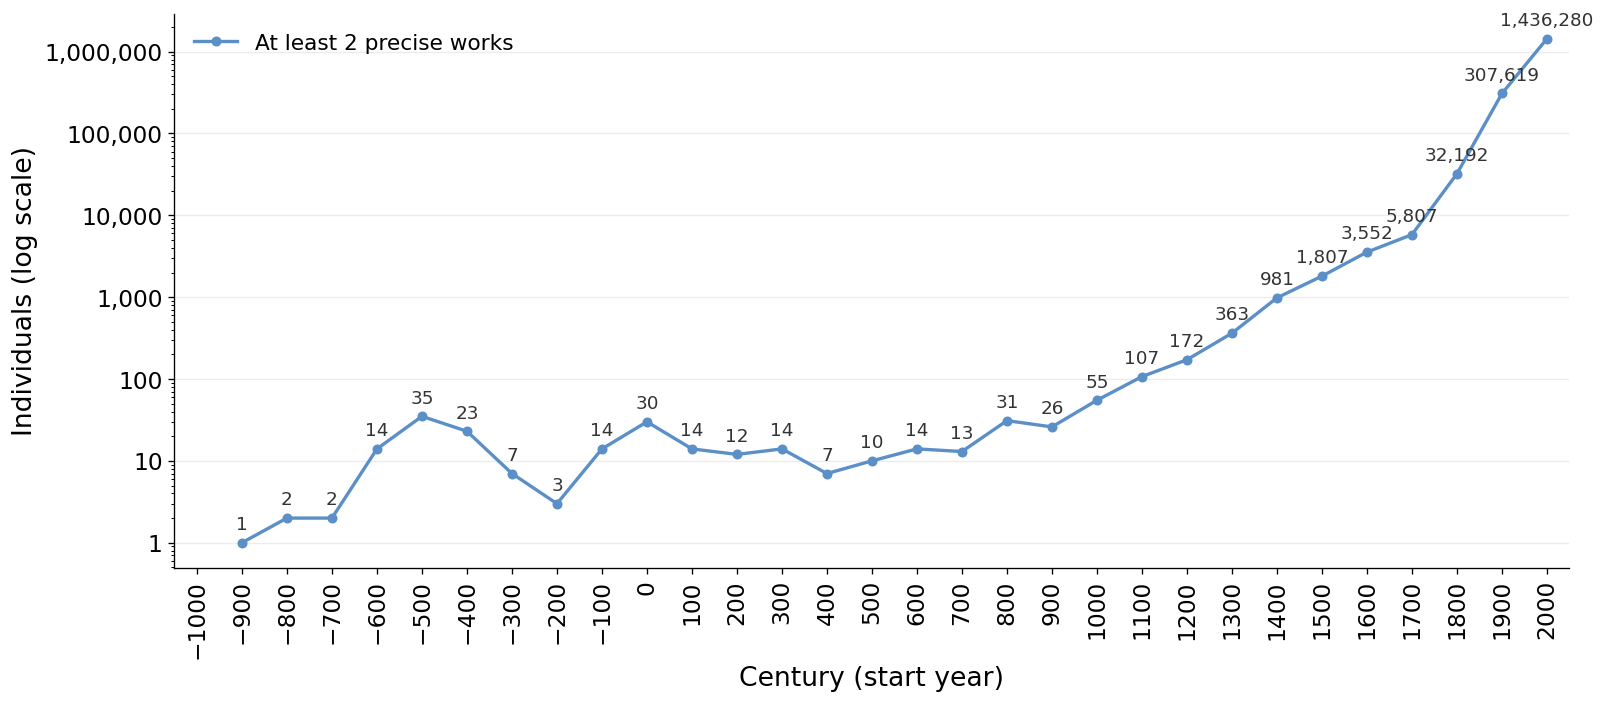

In [6]:
plot_centuries({'At least 2 precise works': two_precise_century}, labelled=['At least 2 precise works'])

### One example per century
The individual with the most Wikimedia pages among those whose first precise work falls in the century, with their two earliest precise works that have a title. Long titles are cut at 50 characters.

30 centuries, 30 in the chart


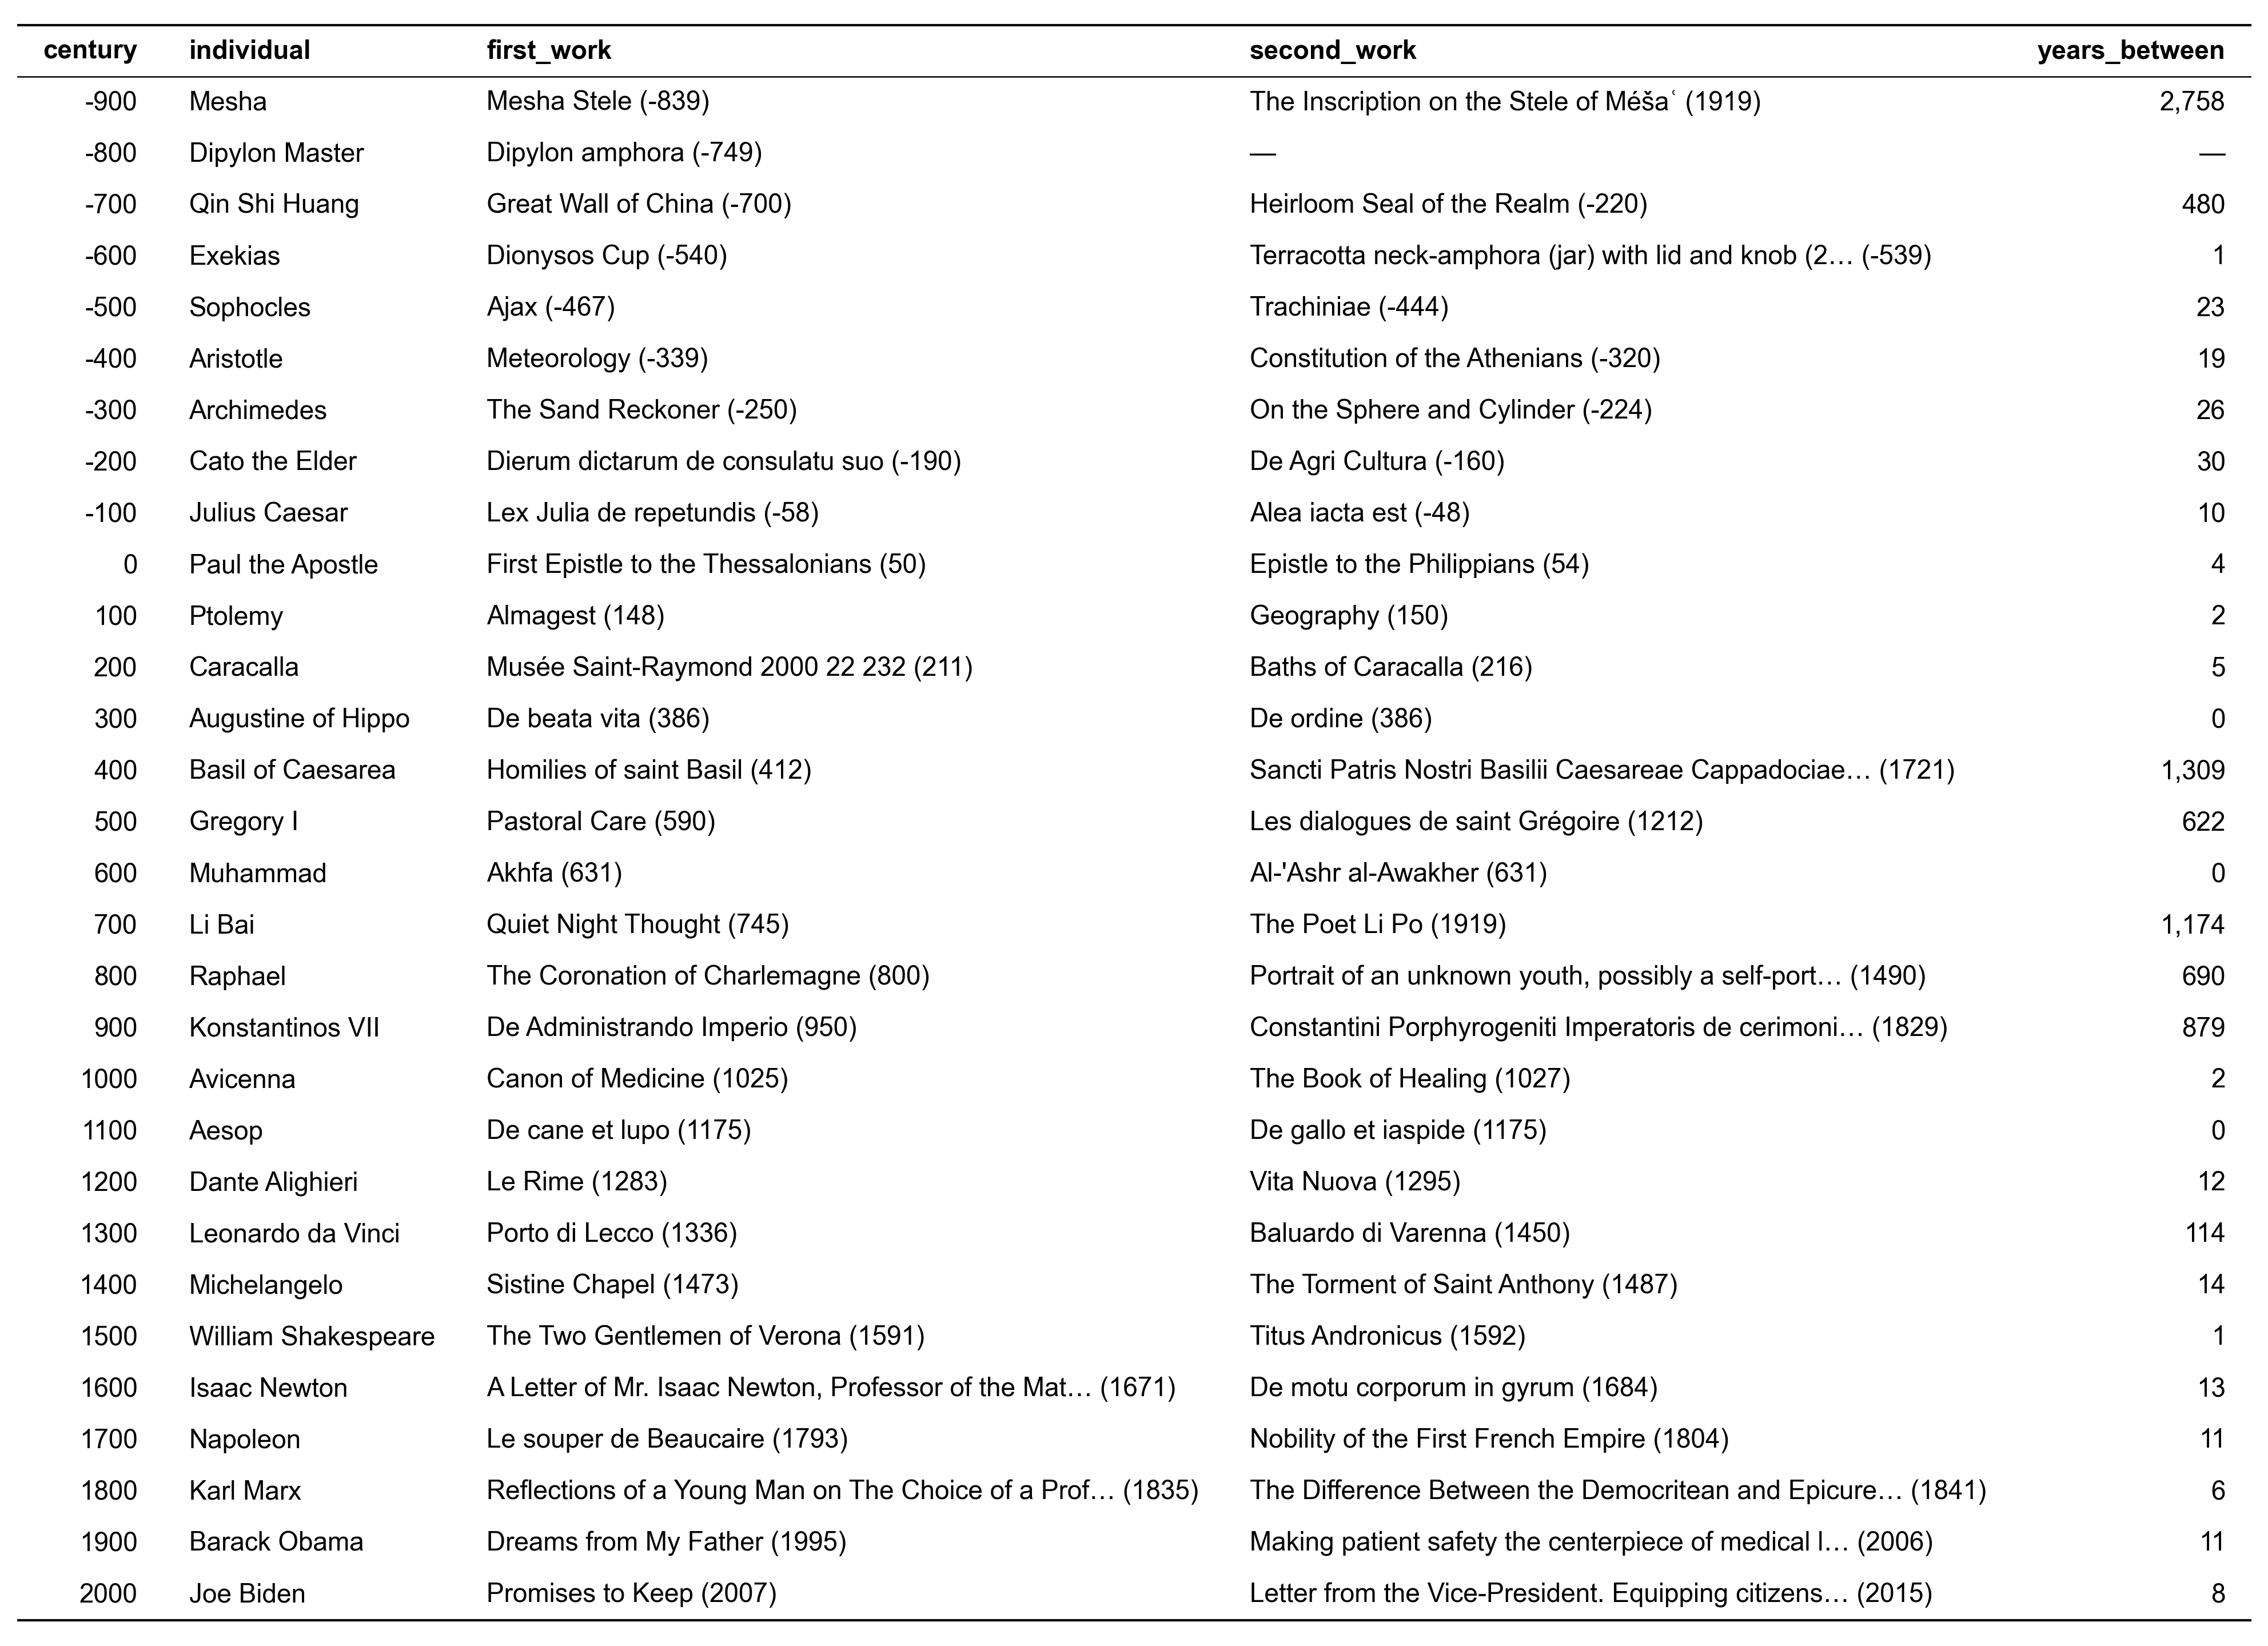

In [7]:
examples_input = two_precise.with_columns((pl.col('first_precise_year') // 100 * 100).alias('century_start')).filter(
    pl.col('century_start').is_between(FIRST_CENTURY, LAST_CENTURY)).select('qid', 'century_start')
connection.register('examples_input', examples_input.to_arrow())

examples = connection.execute('''
    WITH best AS (
        SELECT examples_input.century_start, examples_input.qid,
               coalesce(individual.entity.label_en, individual.entity.label_non_en) AS individual
        FROM examples_input
        JOIN individual ON individual.entity.qid = examples_input.qid
        QUALIFY row_number() OVER (PARTITION BY examples_input.century_start ORDER BY len(individual.sitelink) DESC, examples_input.qid) = 1
    ),
    dated AS (
        SELECT best.century_start, best.individual,
               coalesce(work.entity.label_en, work.entity.label_non_en) AS work,
               coalesce(work.publication_date.year, work.inception.year) AS year,
               CASE WHEN work.publication_date.year IS NOT NULL THEN work.publication_date.precision
                    ELSE work.inception.precision END AS precision
        FROM best
        JOIN individual_work ON individual_work.qid = best.qid
        JOIN work ON work.entity.qid = individual_work.work_qid
    ),
    first_two AS (
        SELECT century_start, individual, year,
               CASE WHEN length(work) > 50 THEN left(work, 50) || '…' ELSE work END || ' (' || year || ')' AS work,
               row_number() OVER (PARTITION BY century_start ORDER BY year, work) AS position
        FROM dated
        WHERE precision IN ('day', 'month', 'year', 'decade') AND work IS NOT NULL
        QUALIFY position <= 2
    )
    SELECT century_start AS century, individual,
           max(work) FILTER (WHERE position = 1) AS first_work,
           max(work) FILTER (WHERE position = 2) AS second_work,
           max(year) FILTER (WHERE position = 2) - max(year) FILTER (WHERE position = 1) AS years_between
    FROM first_two
    GROUP BY ALL
    ORDER BY century_start
''').pl().with_columns(pl.col('century').cast(pl.String))
print(f'{examples.height} centuries, {two_precise_century.height} in the chart')
show_table(examples)

## 2. Individuals with only one work dated to the year or decade

In [8]:
one_work = works.filter(pl.col('precise_works') == 1)
print(f'{one_work.height:,} individuals with exactly one year- or decade-precise work')

984,063 individuals with exactly one year- or decade-precise work


### By century of that work

In [9]:
one_work_century = by_century(one_work, 'first_precise_year')
one_work_century

11 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals
i64,u32
-900,1
-700,2
-600,33
-500,37
-400,45
-300,4
-200,8
-100,18
0,12


### Figure: individuals with only one precise work, by century

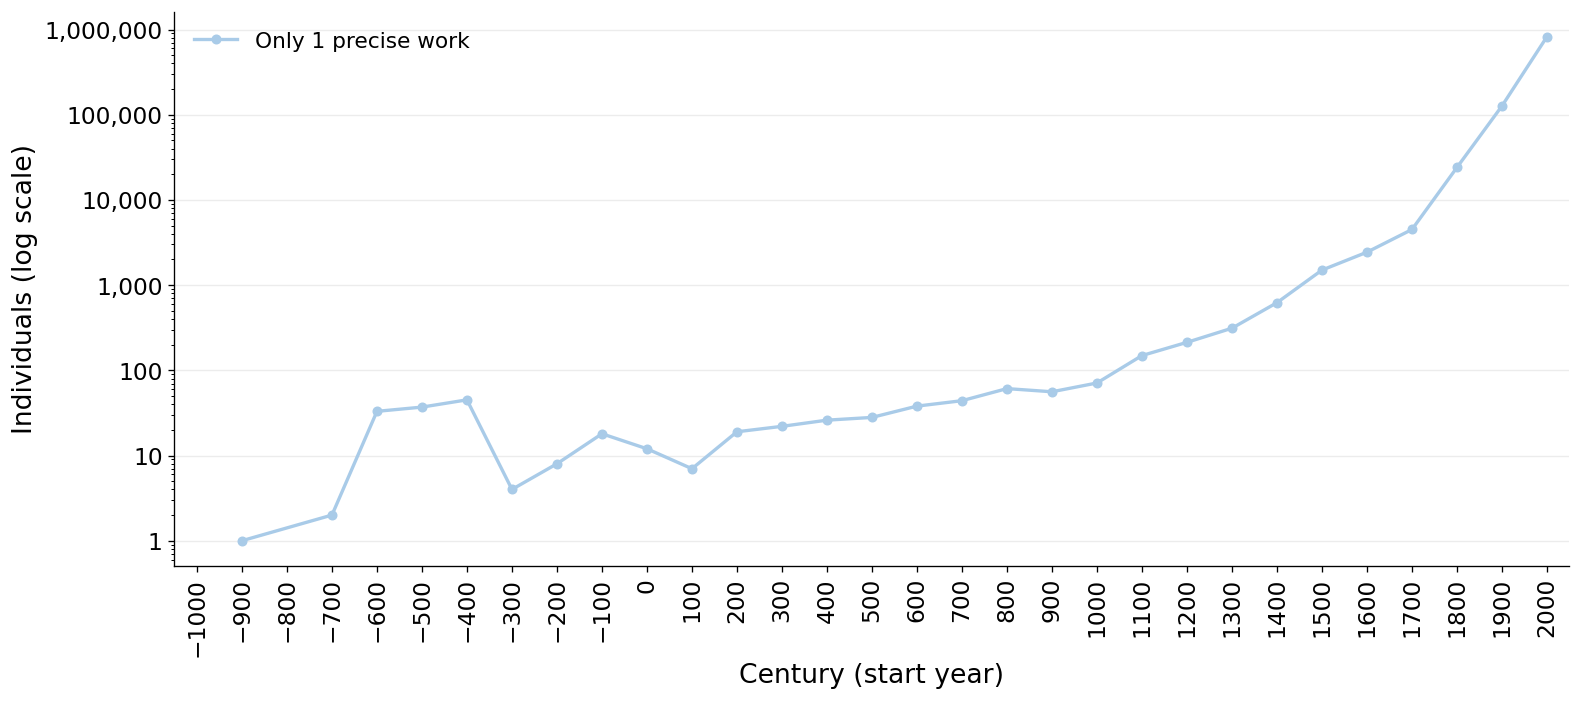

In [10]:
plot_centuries({'Only 1 precise work': one_work_century})

## 3. Both groups together
Individuals with at least one precise work are the two groups above added together; each is placed at the century of their first precise work.

In [11]:
one_or_more_century = (
    two_precise_century.join(one_work_century, on='century_start', how='full', coalesce=True, suffix='_one')
    .fill_null(0)
    .select('century_start', (pl.col('individuals') + pl.col('individuals_one')).alias('individuals'))
    .sort('century_start')
)
assert one_or_more_century['individuals'].sum() == two_precise_century['individuals'].sum() + one_work_century['individuals'].sum()

### Figure: individuals with at least 1 precise work, by century

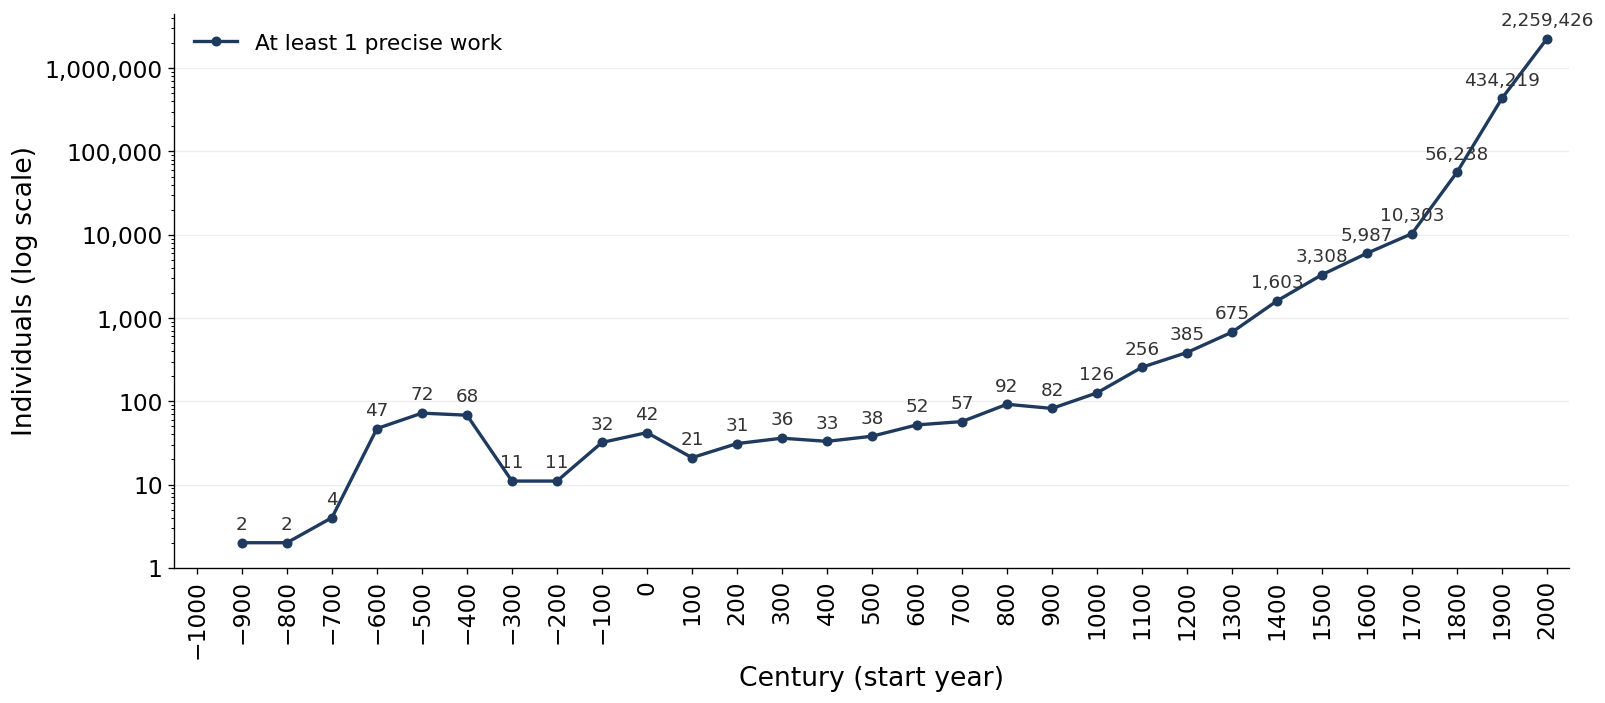

In [12]:
plot_centuries({'At least 1 precise work': one_or_more_century}, labelled=['At least 1 precise work'])

### Figure: individuals with dated works, by century

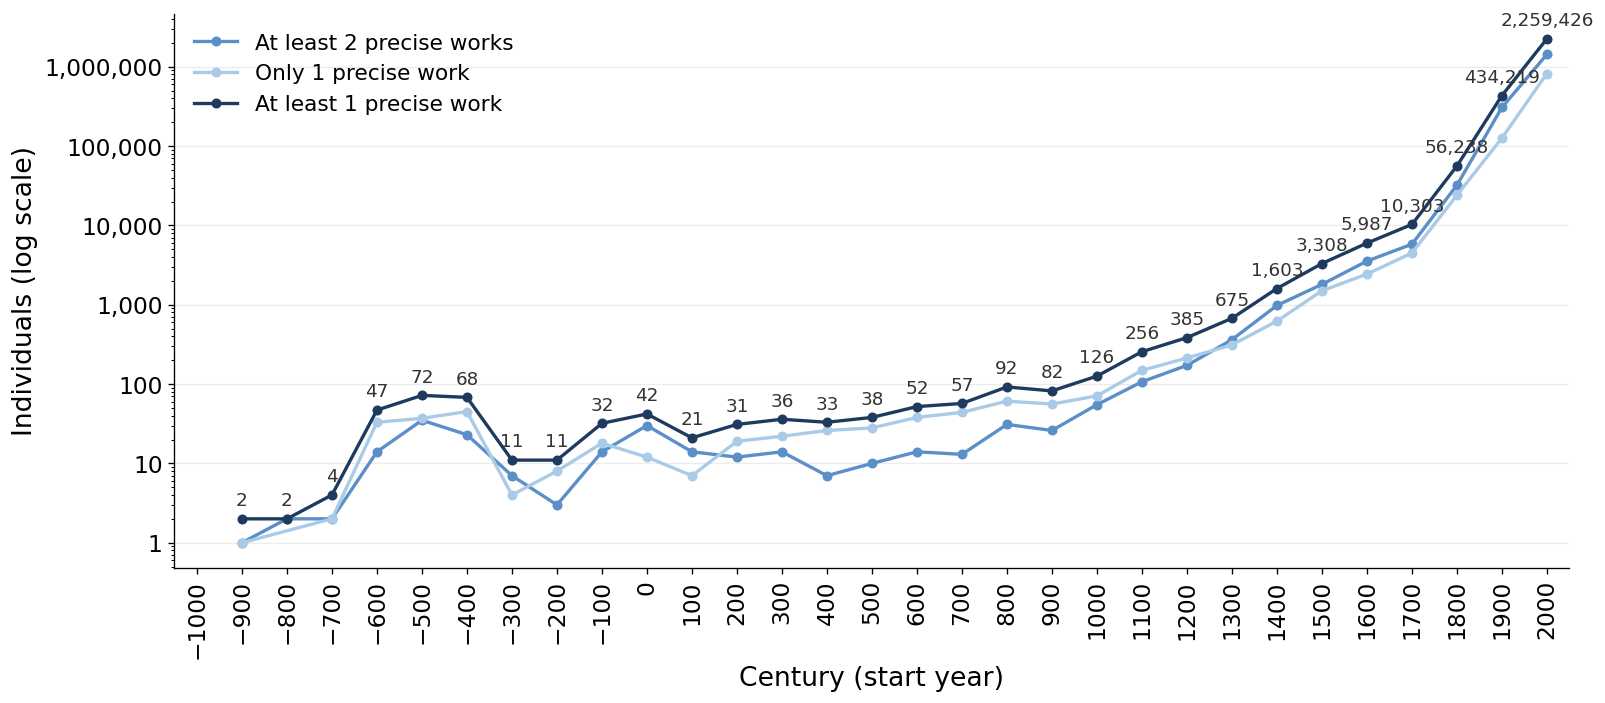

In [13]:
plot_centuries({
    'At least 2 precise works': two_precise_century,
    'Only 1 precise work': one_work_century,
    'At least 1 precise work': one_or_more_century,
}, labelled=['At least 1 precise work'])

### Table: individuals with dated works, by century
The total row also counts individuals placed outside 1000 BCE – 2099.

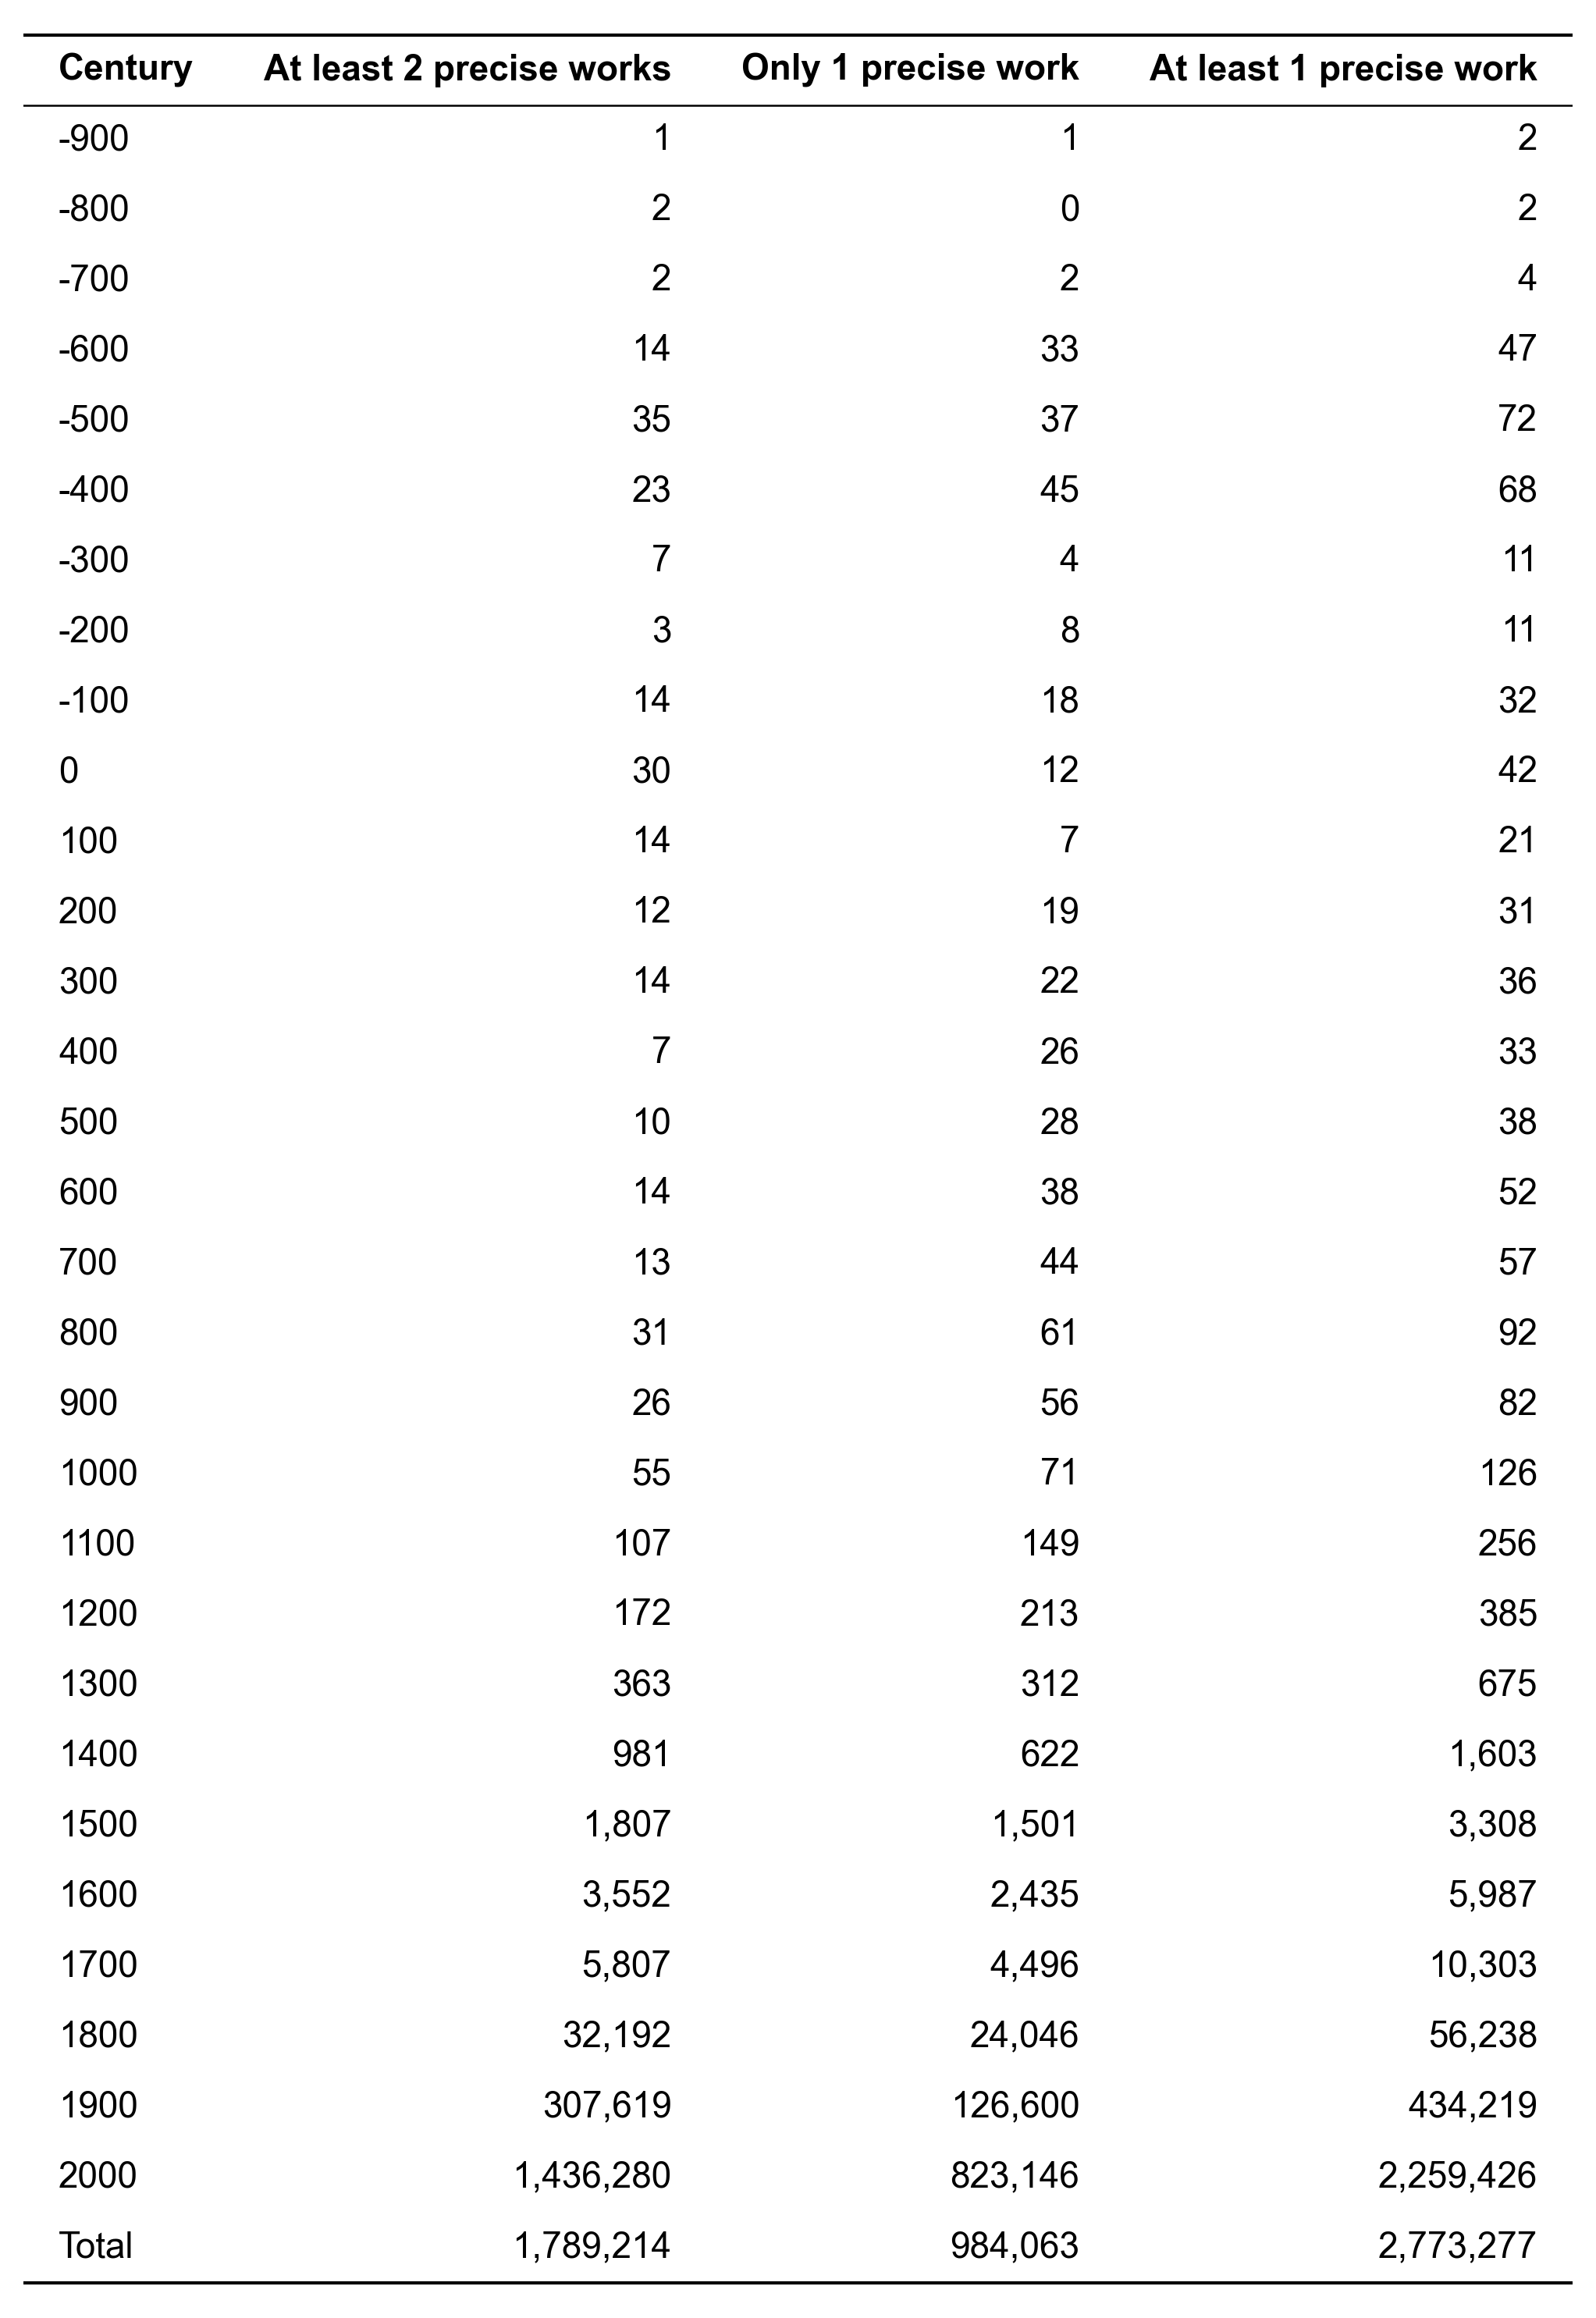

In [14]:
summary = (
    two_precise_century.rename({'individuals': 'At least 2 precise works'})
    .join(one_work_century.rename({'individuals': 'Only 1 precise work'}), on='century_start', how='full', coalesce=True)
    .join(one_or_more_century.rename({'individuals': 'At least 1 precise work'}), on='century_start', how='full', coalesce=True)
    .fill_null(0)
    .sort('century_start')
    .with_columns(pl.col('century_start').cast(pl.String))
    .rename({'century_start': 'Century'})
)
total_row = pl.DataFrame({
    'Century': ['Total'],
    'At least 2 precise works': [two_precise.height],
    'Only 1 precise work': [one_work.height],
    'At least 1 precise work': [two_precise.height + one_work.height],
})
show_table(pl.concat([summary, total_row], how='vertical_relaxed'))